# Bài thực hành 1

## Vấn đề
_Dự đoán khả năng tiến triển của bệnh tiểu đường thông qua các chỉ số sinh lý của cơ thể._


## Thông tin dữ liệu:

- Số lượng mẫu: 442 (thông tin từ 442 bệnh nhân)
- Số lượng thuộc tính:
    Thông tin các thuộc tính (10 cột giá trị đầu tiên): Age(tuổi), Sex (giới tính),
    Body mass index (chỉ số khối cơ thể), Average blood pressure(huyết ap trung bình), S1, S2, S3, S4, S5, S6 (sáu phép đo huyết thanh khác).
- Mục tiêu:	Cột 11, chỉ số đánh giá mức độ tiến triển của bệnh 1 năm sau khi điều trị.

**! Chú ý: Dữ liệu thông tin thuộc tính đã được chuẩn hoá**

Xem thêm thông tin về nguồn dữ liệu tại: (https://www4.stat.ncsu.edu/~boos/var.select/diabetes.html)


# Hướng giải quyết

Giả sử rằng khả năng tiến triển của bệnh tiểu đường (ký hiệu: `y`) là đại lượng phụ thuộc tuyến tính vào các thông tin sinh lý của bệnh nhân như các thuộc tính đã mô tả ở trên (tuổi, giới tính, chỉ số khối, ... - ký hiệu: `x1, x2, .. x_n`) :

`y = w0 + w1*x1 + w2*x2 + ... + w_n*x_n`

Mục tiêu: Tìm được bộ trọng số `[w0, w1, ... w_n]` biểu diễn mối quan hệ này.

#Các bước tiến hành

## Thư viện sử dụng

- matplotlib: phục vụ vẽ các đồ thị
- numpy: tính toán các phép biến đổi trên ma trận / vector
- math: thực hiện một số hàm tính toán
- pandas: phục vụ chuyển đổi trên dữ liệu dạng bảng
- scikit-learn: (sklearn) thư viện hỗ trợ xây dựng các mô hình học máy, các hàm training và testing.


In [1]:
!pip install pandas

In [3]:
!pip install scikit-learn matplotlib


  Using cached scipy-1.18.1-cp314-cp314-win_amd64.whl.metadata (61 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached threadpoolctl-3.7.0-py3-none-any.whl.metadata (24 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   ------------------------------------

In [4]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import math

from sklearn import datasets, linear_model
from sklearn.metrics import mean_squared_error, r2_score


## Đọc dữ liệu

Dữ liệu về bệnh tiểu đường được hỗ trợ bởi sklearn, đọc dữ liệu thông qua hàm `datasets.load_diabetes()`

Xem thêm các bộ dữ liệu khác tại https://scikit-learn.org/stable/datasets/index.html#toy-datasets.
https://scikit-learn.org/stable/datasets/toy_dataset.html

Dữ liệu nhận về ở dạng object với các thành phần thuộc tính:

- data: ma trận 2 chiều (442x10) - các thông tin bệnh nhân được chuẩn hoá về dạng số thực.
- target: mảng các số thực (442,) - chỉ số tiến triển của bệnh tiểu đường.

In [5]:
# lay du lieu diabetes - du lieu ve benh tieu duong
diabetes = datasets.load_diabetes()
print("Số chiều dữ liệu input: ", diabetes.data.shape)
print("Kiểu dữ liệu input: ", type(diabetes.data))
print("Số chiều dữ liệu target: ", diabetes.target.shape)
print("Kiểu dữ liệu target: ", type(diabetes.target))
print()

print("5 mẫu dữ liệu đầu tiên:")
print("input: ", diabetes.data[:5])
print("target: ",diabetes.target[:5])
#print("data[5,1]", diabetes.data[4,1])

Số chiều dữ liệu input:  (442, 10)
Kiểu dữ liệu input:  <class 'numpy.ndarray'>
Số chiều dữ liệu target:  (442,)
Kiểu dữ liệu target:  <class 'numpy.ndarray'>

5 mẫu dữ liệu đầu tiên:
input:  [[ 0.03807591  0.05068012  0.06169621  0.02187239 -0.0442235  -0.03482076
  -0.04340085 -0.00259226  0.01990749 -0.01764613]
 [-0.00188202 -0.04464164 -0.05147406 -0.02632753 -0.00844872 -0.01916334
   0.07441156 -0.03949338 -0.06833155 -0.09220405]
 [ 0.08529891  0.05068012  0.04445121 -0.00567042 -0.04559945 -0.03419447
  -0.03235593 -0.00259226  0.00286131 -0.02593034]
 [-0.08906294 -0.04464164 -0.01159501 -0.03665608  0.01219057  0.02499059
  -0.03603757  0.03430886  0.02268774 -0.00936191]
 [ 0.00538306 -0.04464164 -0.03638469  0.02187239  0.00393485  0.01559614
   0.00814208 -0.00259226 -0.03198764 -0.04664087]]
target:  [151.  75. 141. 206. 135.]


**Chia dữ liệu làm 2 phần training 362 mẫu và testing 80 mẫu**

In [6]:
# cat nho du lieu, lay 1 phan cho qua trinh thu nghiem,
# chia train test cac mau du lieu
# diabetes_X = diabetes.data[:, np.newaxis, 2]
diabetes_X = diabetes.data

diabetes_X_train = diabetes_X[:361]
diabetes_y_train = diabetes.target[:361]

diabetes_X_test = diabetes_X[362:]
diabetes_y_test = diabetes.target[362:]

## Xây dựng mô hình Regression sử dụng Sklearn

Thử nghiệm xây dựng mô hình hồi quy (Linear Regression / Ridge Regression) để học được bộ tham số

- [Linear Regression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html) `linear_model.LinearRegression()`
- [Ridge Regression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html#sklearn.linear_model.Ridge) `linear_model.Ridge()`

In [7]:
# Xay dung model su dung sklearn
regr = linear_model.LinearRegression()


In [8]:
regr_ridge = linear_model.Ridge(alpha=0.1)

## Training mô hình

Sử dụng Dữ liệu đã được chia ở bước trước đó để thực hiện training model.

=> Tìm được bộ trọng số `[w0, w1, ... w_n]`

In [9]:
# Huấn luyện mô hình Linear Regression
regr.fit(diabetes_X_train, diabetes_y_train)
print("[w1, ... w_n] = ", regr.coef_)
print("w0 = ", regr.intercept_)

[w1, ... w_n] =  [-1.12982324e-02 -2.49782541e+02  5.18802202e+02  2.97220454e+02
 -6.39802236e+02  3.56330510e+02  2.77834385e+01  1.46962789e+02
  6.90474996e+02  1.05716702e+02]
w0 =  152.56041961097782


In [10]:
regr_ridge.fit(diabetes_X_train, diabetes_y_train)
print("[w1, ... w_n] = ", regr_ridge.coef_)
print("w0 = ", regr_ridge.intercept_)

[w1, ... w_n] =  [  10.51523842 -215.21946642  477.04576811  275.18547584  -64.84522547
  -82.84458659 -194.22465786  112.99561167  427.19001456  121.18397114]
w0 =  152.57401415344637


In [12]:
##### exercise #####
# Yêu cầu: tính giá trị dự đoán của mô hình trên mẫu đầu tiên của tập test và so sánh với kết quả của thư viện
# Gợi ý: sử dụng công thức y = w0 + w1*x1 + w1*x2 + ... + w_n*x_n
######################
#Dự đoán thử cho trường hợp đầu tiên

#Giá trị đúng
print("Gia tri true: ", diabetes_y_test[0])

#Dự đoán cho mô hình Linear Regression sử dụng hàm dự đoán của thư viện
y_pred_linear = regr.predict(diabetes_X_test[0:1])
print("Gia tri du doan cho mô hình linear regression: ", y_pred_linear)

#Viết code tính và in kết quả dự đoán cho mô hình Linear Regression sử dụng công thức tại đây
y_pred_linear_formula = regr.intercept_ + np.dot(diabetes_X_test[0] ,regr.coef_)
print("Gia tri tinh bang cong thuc: ", y_pred_linear_formula)

#Dự đoán cho mô hình Ridge Regression sử dụng hàm dự đoán của thư viện
y_pred_ridge = regr_ridge.predict(diabetes_X_test[0:1])
print("Gia tri du doan cho mô hình ridge regression: ", y_pred_ridge)

#Viết code tính và in kết quả dự đoán cho mô hình Ridge Regression sử dụng công thức tại đây
y_pred_ridge_formula = regr_ridge.intercept_ + np.dot(diabetes_X_test[0], regr_ridge.coef_)
print("Gia tri tinh bang cong thuc: ", y_pred_ridge_formula)

######################

Gia tri true:  321.0
Gia tri du doan cho mô hình linear regression:  [234.35947872]
Gia tri tinh bang cong thuc:  234.35947872322677
Gia tri du doan cho mô hình ridge regression:  [226.73474004]
Gia tri tinh bang cong thuc:  226.73474004055703


## Dự đoán các mẫu dữ liệu trong tập test

In [14]:
# Thực hiện suy diễn sau khi huấn luyện
diabetes_y_pred = regr.predict(diabetes_X_test)
pd.DataFrame(data=np.array([diabetes_y_test, diabetes_y_pred,
                            abs(diabetes_y_test - diabetes_y_pred)]).T,
             columns=["Thực tế", "Dự đoán", "Lệch"])

diabetes_y_pred_ridge = regr_ridge.predict(diabetes_X_test)
pd.DataFrame(data=np.array([diabetes_y_test, diabetes_y_pred_ridge,
                            abs(diabetes_y_test - diabetes_y_pred_ridge)]).T,
             columns=["Thực tế", "Dự đoán", "Lệch"])

# pd.DataFrame(data=np.array([diabetes_y_test, diabetes_y_pred,
#                             abs(diabetes_y_test - diabetes_y_pred)]),
#              index=["Thực tế", "Dự đoán", "Lệch"])

,Thực tế,Dự đoán,Lệch
0,321.0,226.734740,94.265260
1,58.0,160.362117,102.362117
2,262.0,163.440461,98.559539
3,206.0,165.882673,40.117327
4,233.0,249.611342,16.611342
...,...,...,...
75,178.0,187.982157,9.982157
76,104.0,112.747621,8.747621
77,132.0,128.295963,3.704037
78,220.0,202.798449,17.201551


## Đánh giá

Sử dụng độ đo RMSE tính căn bậc 2 của trung bình bình phương lỗi.
> $\text{RMSE}(y, \hat{y}) = \sqrt{\frac{1}{n_\text{samples}} \sum_{i=0}^{n_\text{samples} - 1} (y_i - \hat{y}_i)^2}.$

- Lỗi càng nhỏ càng thể hiện mô hình có khả năng học và dự đoán hiệu quả
- Như thế nào là nhỏ ?

In [15]:
# Giá trị RMSE của mô hình Linear Regression
math.sqrt(mean_squared_error(diabetes_y_test, diabetes_y_pred))

51.53921127468042

In [18]:
##### exercise #####
# Yêu cầu: đánh giá độ đo RMSE của mô hình Ridge Regression với các hằng số phạt khác nhau, in ra kết quả.
# Gợi ý: Các bước làm:
# - Lặp theo danh sách các hằng số phạt
# - Dựng các mô hình Ridge Regression với mỗi hằng số phạt tương ứng
# - Huấn luyện các mô hình và dự đoán
# - Tính RMSE tương ứng
######################

#Các giá trị hằng số phạt cho trước
_lambda = [0, 0.0001,0.01, 0.04, 0.05, 0.06, 0.1, 0.5, 1, 5, 10, 20]

best_lam, best_rmse = 0, 100
for lam in _lambda:
    regr_ridge_lam = linear_model.Ridge(alpha=lam)
    regr_ridge_lam.fit(diabetes_X_train, diabetes_y_train)
    y_pred_ridge_lam = regr_ridge_lam.predict(diabetes_X_test)
    rmse = math.sqrt(mean_squared_error(diabetes_y_test, y_pred_ridge_lam))
    print("alpha=", lam, ", RMSE=", rmse, end='\n')
    best_rmse = min(best_rmse, rmse)
    if best_rmse == rmse: best_lam = lam

print("Gia tri alpha tot nhat: ", best_lam)

alpha= 0 , RMSE= 51.53921127468042
alpha= 0.0001 , RMSE= 51.546352409239816
alpha= 0.01 , RMSE= 51.888660697856096
alpha= 0.04 , RMSE= 52.11211596712348
alpha= 0.05 , RMSE= 52.15254636221311
alpha= 0.06 , RMSE= 52.19077570036307
alpha= 0.1 , RMSE= 52.347597926523825
alpha= 0.5 , RMSE= 54.613321511474574
alpha= 1 , RMSE= 57.382574887617025
alpha= 5 , RMSE= 67.24133680169886
alpha= 10 , RMSE= 71.18738262709283
alpha= 20 , RMSE= 74.05735936735674
Gia tri alpha tot nhat:  0


In [19]:
!pip install seaborn

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)


### Vẽ biểu đồ phân phối cho chỉ số thực tế

C:\Users\Asus\AppData\Local\Temp\ipykernel_16236\2026487888.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(diabetes_y_test)


,values
count,80.00000
mean,152.38750
std,78.46994
min,40.00000
25%,72.00000
50%,140.00000
75%,217.50000
max,321.00000


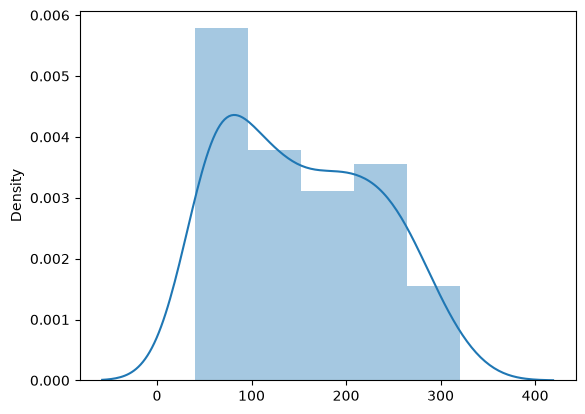

In [20]:
import seaborn as sns
sns.distplot(diabetes_y_test)
pd.DataFrame(data=diabetes_y_test, columns=["values"]).describe()

### Vẽ biểu đồ phân phối cho chỉ số dự đoán của mô hình linear regression

C:\Users\Asus\AppData\Local\Temp\ipykernel_16236\1946324415.py:6: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(diabetes_y_pred)


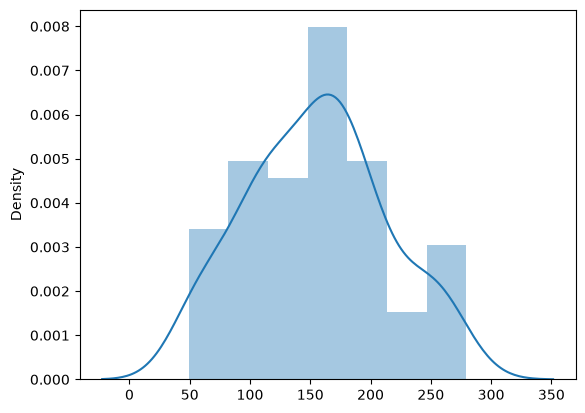

,values
count,80.000000
mean,155.501049
std,57.511599
min,49.193721
25%,112.399159
50%,161.143223
75%,191.047878
max,279.598577


In [21]:
##### exercise #####
# Yêu cầu: Tính các chỉ số thống kê và vẽ biểu đồ phân phối của chỉ số dự đoán bằng mô hình Linear Regression, quan sát và nhận xét
# Gợi ý: sử dụng sns và pd
######################

sns.distplot(diabetes_y_pred)
plt.show()
pd.DataFrame(data=diabetes_y_pred, columns=["values"]).describe()

### Vẽ biểu đồ so sánh kết quả dự đoán và thực tế

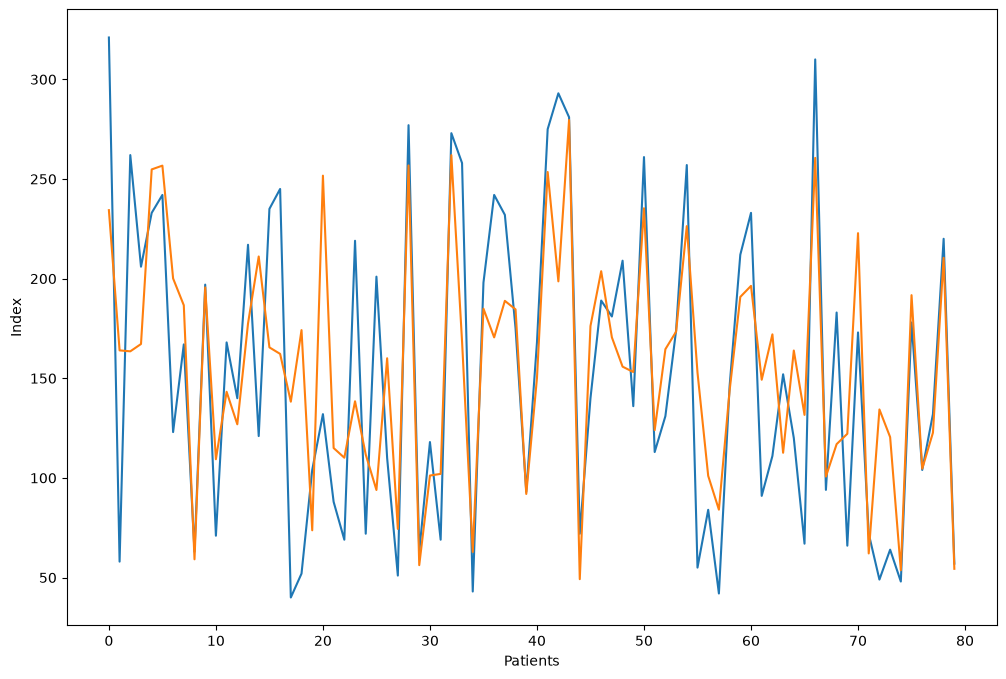

In [22]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,8))

plt.plot(diabetes_y_test)
plt.plot(diabetes_y_pred)

plt.xlabel('Patients')

plt.ylabel('Index')


# function to show the plot
plt.show()

In [24]:
from sklearn import linear_model

# ==============================================================================
# 1. Chuẩn bị 3 mô hình
# ==============================================================================
# Mô hình 1: Ordinary Least Squares (OLS tương đương alpha = 0)
alpha_ols = 0
model_ols = regr

# Mô hình 2: Ridge với alpha tốt nhất từ kết quả khảo sát (biến best_lam)
alpha_ridge = best_lam  # Giá trị tốt nhất đã tìm được ở bước trước (= 0)
model_ridge = linear_model.Ridge(alpha=alpha_ridge)
model_ridge.fit(diabetes_X_train, diabetes_y_train)

# Mô hình 3: LASSO (huấn luyện thêm với alpha = 0.1)
alpha_lasso = 0.1
model_lasso = linear_model.Lasso(alpha=alpha_lasso)
model_lasso.fit(diabetes_X_train, diabetes_y_train)

# ==============================================================================
# 2. Tính Test RSS trên tập test
# ==============================================================================
pred_ols = model_ols.predict(diabetes_X_test)
pred_ridge = model_ridge.predict(diabetes_X_test)
pred_lasso = model_lasso.predict(diabetes_X_test)

rss_ols = np.sum((diabetes_y_test - pred_ols) ** 2)
rss_ridge = np.sum((diabetes_y_test - pred_ridge) ** 2)
rss_lasso = np.sum((diabetes_y_test - pred_lasso) ** 2)

# ==============================================================================
# 3. Thu thập hàng 'alpha', hàng '0' (w0), các trọng số w_i và Test RSS
# ==============================================================================
# Thêm 'alpha' vào đầu danh sách hàng
row_indices = ['alpha', '0'] + list(diabetes.feature_names) + ['Test RSS']

data_ols = [alpha_ols, model_ols.intercept_] + list(model_ols.coef_) + [rss_ols]
data_ridge = [alpha_ridge, model_ridge.intercept_] + list(model_ridge.coef_) + [rss_ridge]
data_lasso = [alpha_lasso, model_lasso.intercept_] + list(model_lasso.coef_) + [rss_lasso]

# ==============================================================================
# 4. Tạo DataFrame và định dạng hiển thị
# ==============================================================================
df_comparison = pd.DataFrame({
    'Ordinary Least Squares': data_ols,
    'Ridge': data_ridge,
    'LASSO': data_lasso
}, index=row_indices)

df_comparison.index.name = 'w'

# Làm tròn 3 chữ số thập phân
df_comparison = df_comparison.round(3)

# Hiển thị bảng
df_comparison



,Ordinary Least Squares,Ridge,LASSO
w,,,
alpha,0.000,0.000,0.100
0,152.560,152.560,152.559
age,-0.011,-0.011,0.000
sex,-249.783,-249.783,-167.186
bmi,518.802,518.802,512.091
bp,297.220,297.220,248.702
s1,-639.802,-639.802,-51.163
s2,356.331,356.331,-0.000
s3,27.783,27.783,-210.293
